In [1]:
import numpy as np
import cv2
from pathlib import Path
import matplotlib.pyplot as plt
import glob
import math
from typing import Sequence, Union
import re

In [2]:
paths = sorted(glob.glob("/home/filelele/personal_project/belt-conveyor-object-count/dataset/temp/samples_conveyor/dilmah/*.jpg"))
background_paths = paths[:6]
dilmah_paths = paths[6:]

In [3]:
def plot_images(images, cols=4, titles=None, figsize_per_col=4, figsize_per_row=4, ):
    """
    Plots a list of OpenCV images (numpy arrays) in a grid.
    
    :param images: List of images in OpenCV format (BGR or Grayscale).
    :param cols: Number of columns in the grid.
    :param titles: Optional list of titles corresponding to each image.
    :param figsize_per_col: Width allocated per column in inches.
    :param figsize_per_row: Height allocated per row in inches.
    """
    n = len(images)
    if n == 0:
        print("No images to display.")
        return
    cols = min(cols, n)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * figsize_per_col, rows * figsize_per_row))
    
    # Ensure axes is always a flat list/iterable
    if n == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    for idx, img in enumerate(images):
        ax = axes[idx]
        
        # Grayscale vs BGR conversion
        if len(img.shape) == 2:
            ax.imshow(img, cmap='gray')
        elif img.shape[2] == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        elif img.shape[2] == 4:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA))
        else:
            ax.imshow(img)
        if titles and idx < len(titles):
            ax.set_title(titles[idx])
            
        ax.axis('off')
    # Turn off any unused subplots
    for idx in range(n, len(axes)):
        axes[idx].axis('off')
    plt.tight_layout()
    plt.show()

In [4]:
def plot_image_histograms(
    images: Union[np.ndarray, Sequence[np.ndarray]],
    titles: Union[Sequence[str], None] = None,
    bins: int = 256,
    is_bgr: bool = True,
    log_scale: bool = True,       # <-- Set log scale to see bright regions
    ignore_zeros: bool = False    # <-- Set True to ignore dominating black background
):
    """
    Plots images alongside their pixel intensity histograms.
    """
    # Normalize input
    if isinstance(images, np.ndarray):
        if images.ndim == 2:
            img_list = [images]
        elif images.ndim == 3:
            if images.shape[2] in (1, 3, 4):
                img_list = [images]
            else:
                img_list = [images[i] for i in range(images.shape[0])]
        elif images.ndim == 4:
            img_list = [images[i] for i in range(images.shape[0])]
        else:
            raise ValueError(f"Unsupported array shape: {images.shape}")
    else:
        img_list = list(images)
    num_images = len(img_list)
    if num_images == 0:
        return
    if isinstance(titles, str):
        titles = [titles]
    fig, axes = plt.subplots(num_images, 2, figsize=(11, 3.8 * num_images))
    if num_images == 1:
        axes = np.expand_dims(axes, axis=0)
    for i, img in enumerate(img_list):
        title = titles[i] if titles and i < len(titles) else f"Image {i + 1}"
        ax_img, ax_hist = axes[i, 0], axes[i, 1]
        if img.ndim == 3 and img.shape[2] == 1:
            img = img.squeeze(axis=2)
        is_color = (img.ndim == 3 and img.shape[2] in (3, 4))
        # 1. Display Image (explicit vmin/vmax ensures correct display range)
        if is_color:
            display_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if is_bgr else img
            ax_img.imshow(display_img)
        else:
            ax_img.imshow(img, cmap='gray', vmin=0, vmax=255)
            
        ax_img.set_title(title)
        ax_img.axis('off')
        # 2. Display Histogram
        hist_range = [1, 256] if ignore_zeros else [0, 256]
        x_vals = np.linspace(hist_range[0], 255, bins)
        if is_color:
            colors = ('b', 'g', 'r') if is_bgr else ('r', 'g', 'b')
            channel_labels = ('Blue', 'Green', 'Red') if is_bgr else ('Red', 'Green', 'Blue')
            for ch_idx in range(min(3, img.shape[2])):
                hist = cv2.calcHist([img], [ch_idx], None, [bins], hist_range)
                ax_hist.plot(x_vals, hist, color=colors[ch_idx], label=channel_labels[ch_idx], alpha=0.8)
            ax_hist.legend(loc='upper right')
        else:
            hist = cv2.calcHist([img], [0], None, [bins], hist_range)
            ax_hist.plot(x_vals, hist, color='black', label='Intensity')
            ax_hist.fill_between(x_vals, hist.ravel(), color='gray', alpha=0.3)
        if log_scale:
            ax_hist.set_yscale('log')
            ax_hist.set_ylabel("Pixel Count (Log Scale)")
        else:
            ax_hist.set_ylabel("Pixel Count")
        ax_hist.set_title(f"Histogram - {title}")
        ax_hist.set_xlim([0, 255])
        ax_hist.set_xlabel("Pixel Value")
        ax_hist.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

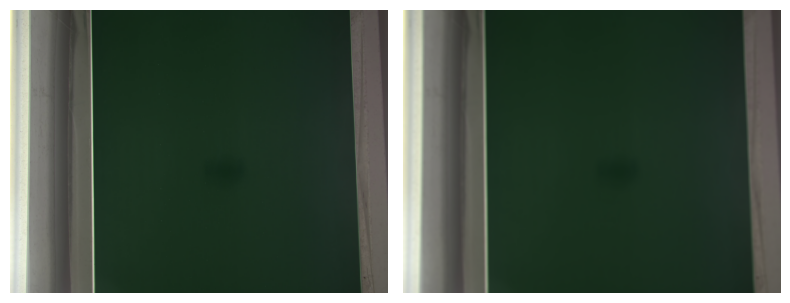

In [20]:
backgrounds = []
for i in range(len(background_paths)):
    mat=cv2.imread(background_paths[i])
    #mat=cv2.resize(mat, None, None, fx=0.125, fy=0.125, interpolation=cv2.INTER_AREA)
    backgrounds.append(mat)
backgrounds = np.array(backgrounds, dtype=np.float32)
mean_background = np.mean(backgrounds, axis=0)
mean_background_blurred = cv2.blur(mean_background, ksize=(17,17))
plot_images([mean_background.astype(np.uint8), mean_background_blurred.astype(np.uint8)])

In [21]:
mean_background.shape

(1536, 2048, 3)

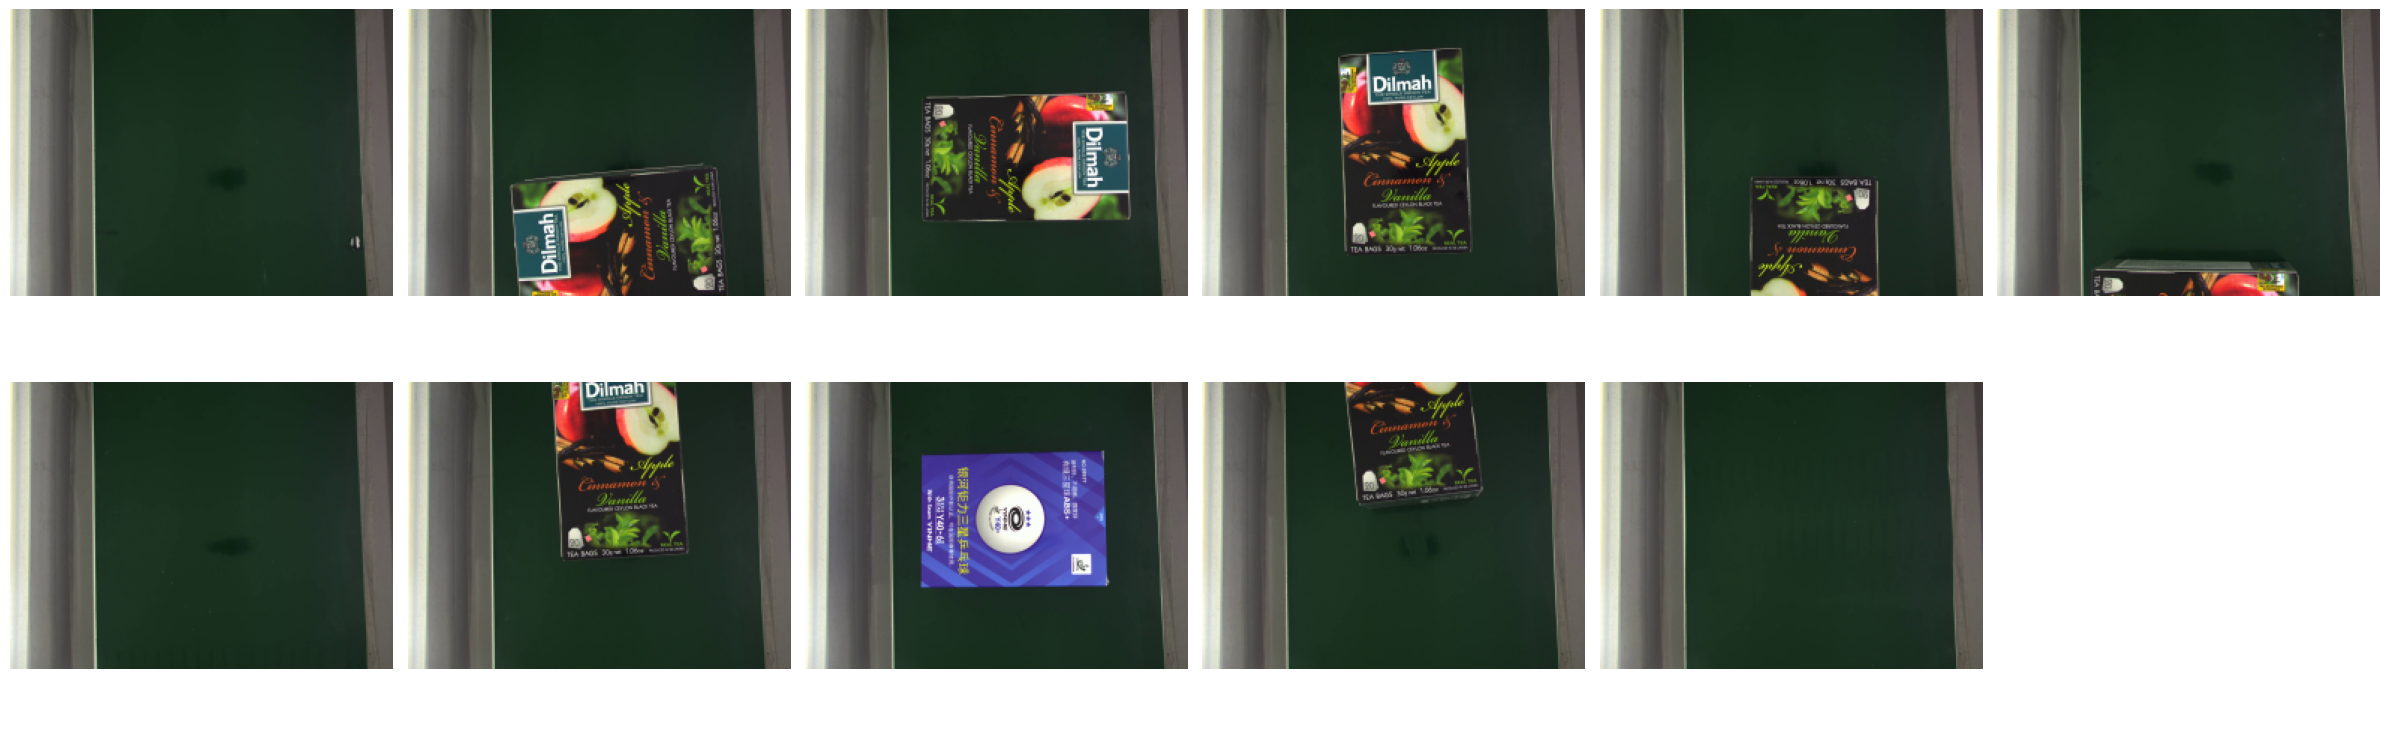

In [7]:
dilmahs = []
for i in range(len(dilmah_paths)):
    mat = cv2.imread(dilmah_paths[i])
    mat=cv2.resize(mat, None, None, fx=0.125, fy=0.125, interpolation=cv2.INTER_AREA)
    dilmahs.append(mat)
    
dilmahs = np.array(dilmahs, dtype=np.float32)
dilmahs_blurred = np.array([cv2.blur(dilmah, ksize=(17,17)) for dilmah in dilmahs], dtype=np.float32)
plot_images(dilmahs.astype(np.uint8), cols=6)

In [8]:
dilmahs_blurred[0].shape

(192, 256, 3)

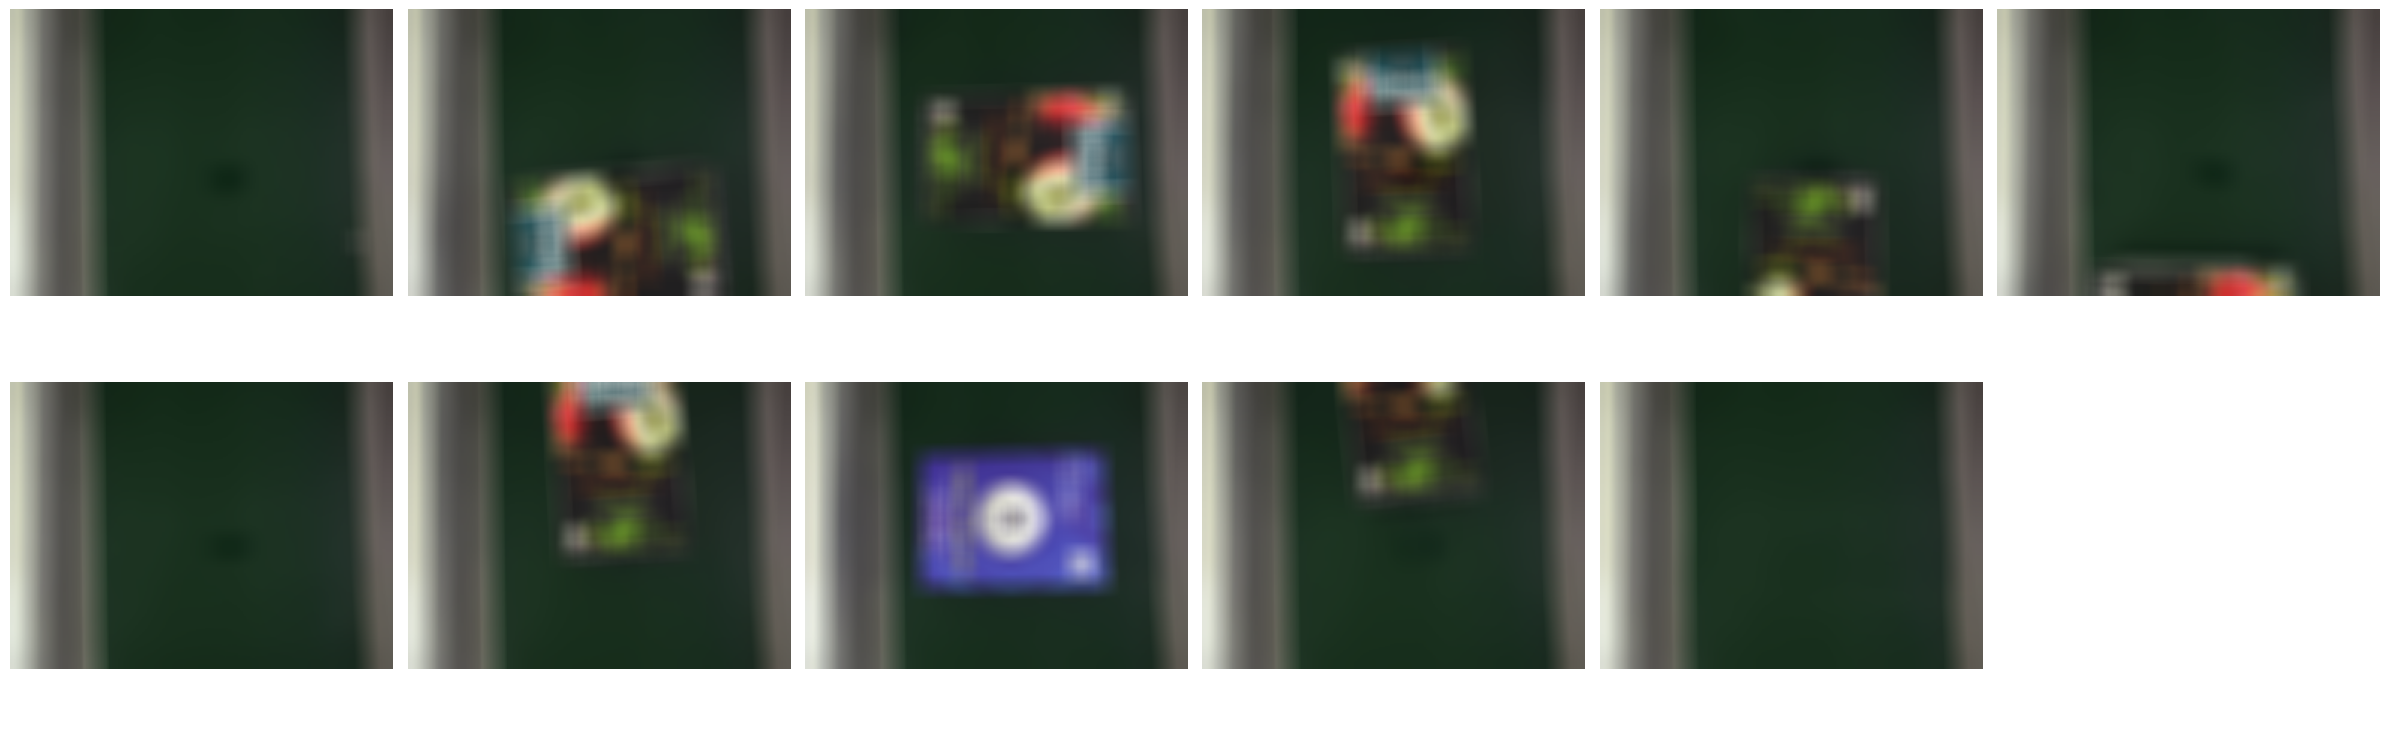

In [9]:
plot_images(dilmahs_blurred.astype(np.uint8), cols=6)

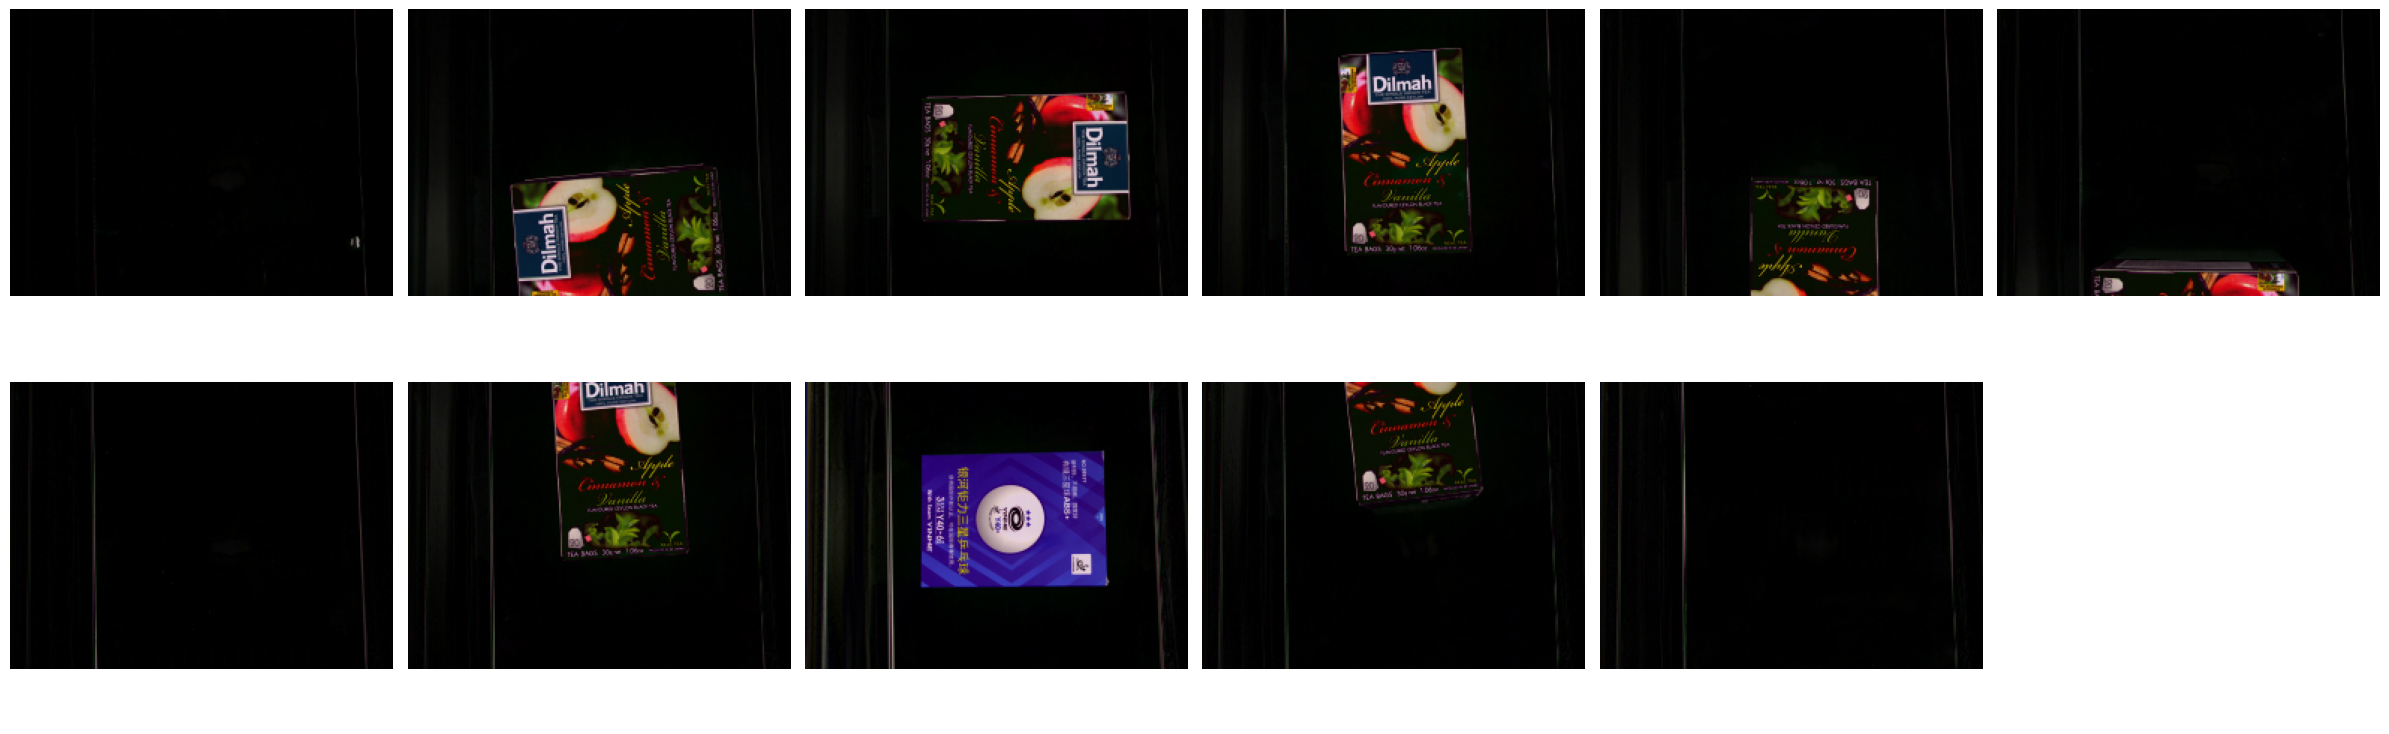

In [10]:
dilmahs_bg_subtracted = np.abs(dilmahs - mean_background)
plot_images(dilmahs_bg_subtracted.astype(np.uint8), cols=6)

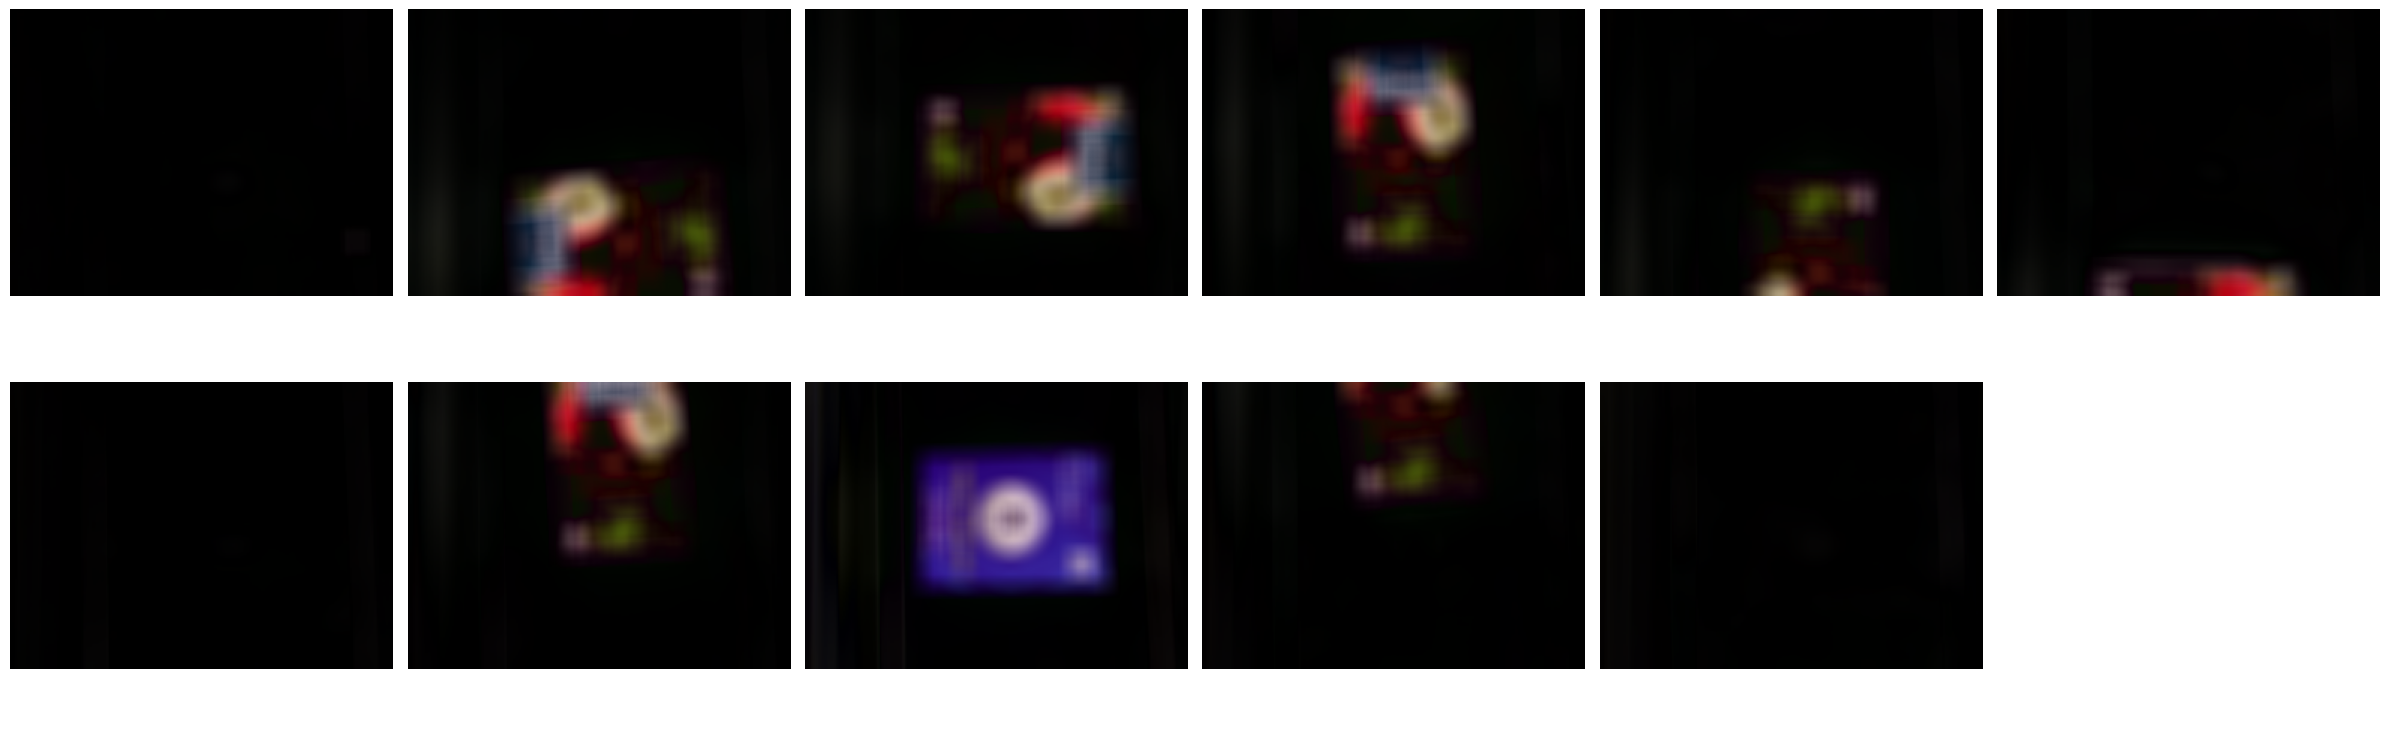

In [11]:
dilmahs_blurred_bg_subtracted = np.abs(dilmahs_blurred - mean_background_blurred)
plot_images(dilmahs_blurred_bg_subtracted.astype(np.uint8), cols=6)

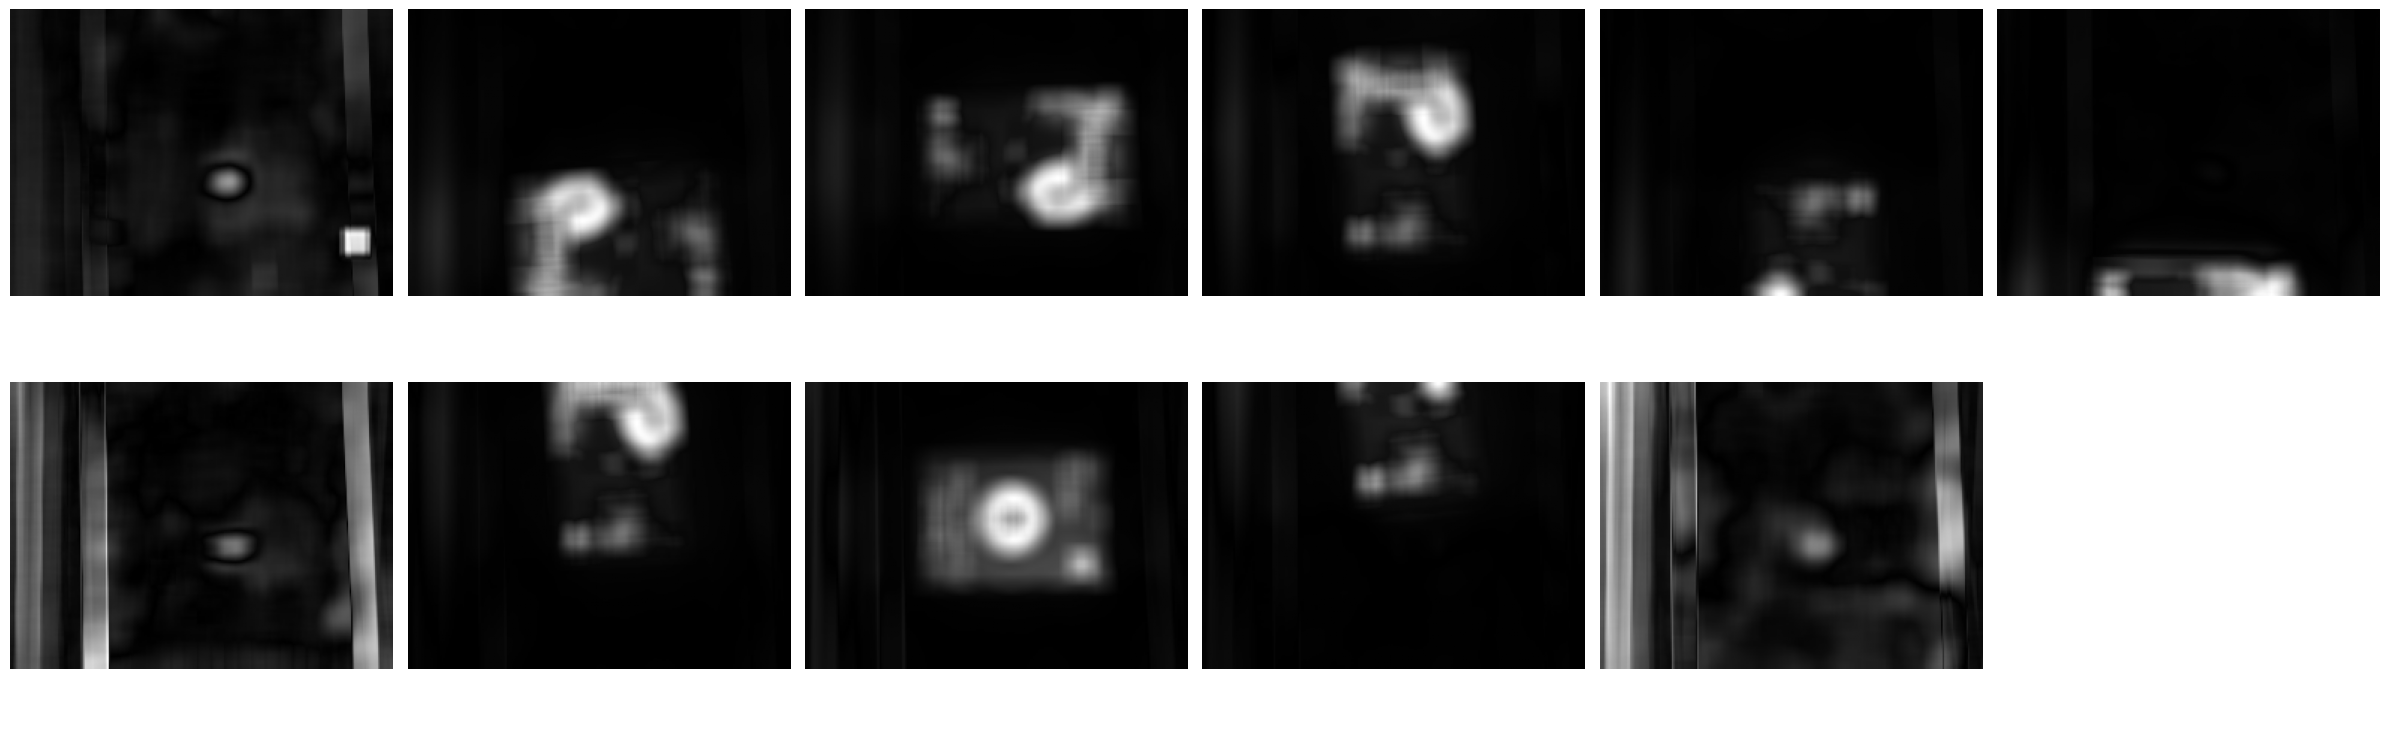

In [12]:
dilmahs_blurred_bg_subtracted_gray = []
for i in range(len(dilmahs_blurred_bg_subtracted)):
    gray = cv2.cvtColor(dilmahs_blurred_bg_subtracted[i], cv2.COLOR_BGR2GRAY)
    dilmahs_blurred_bg_subtracted_gray.append(gray)
plot_images(dilmahs_blurred_bg_subtracted_gray, cols=6)

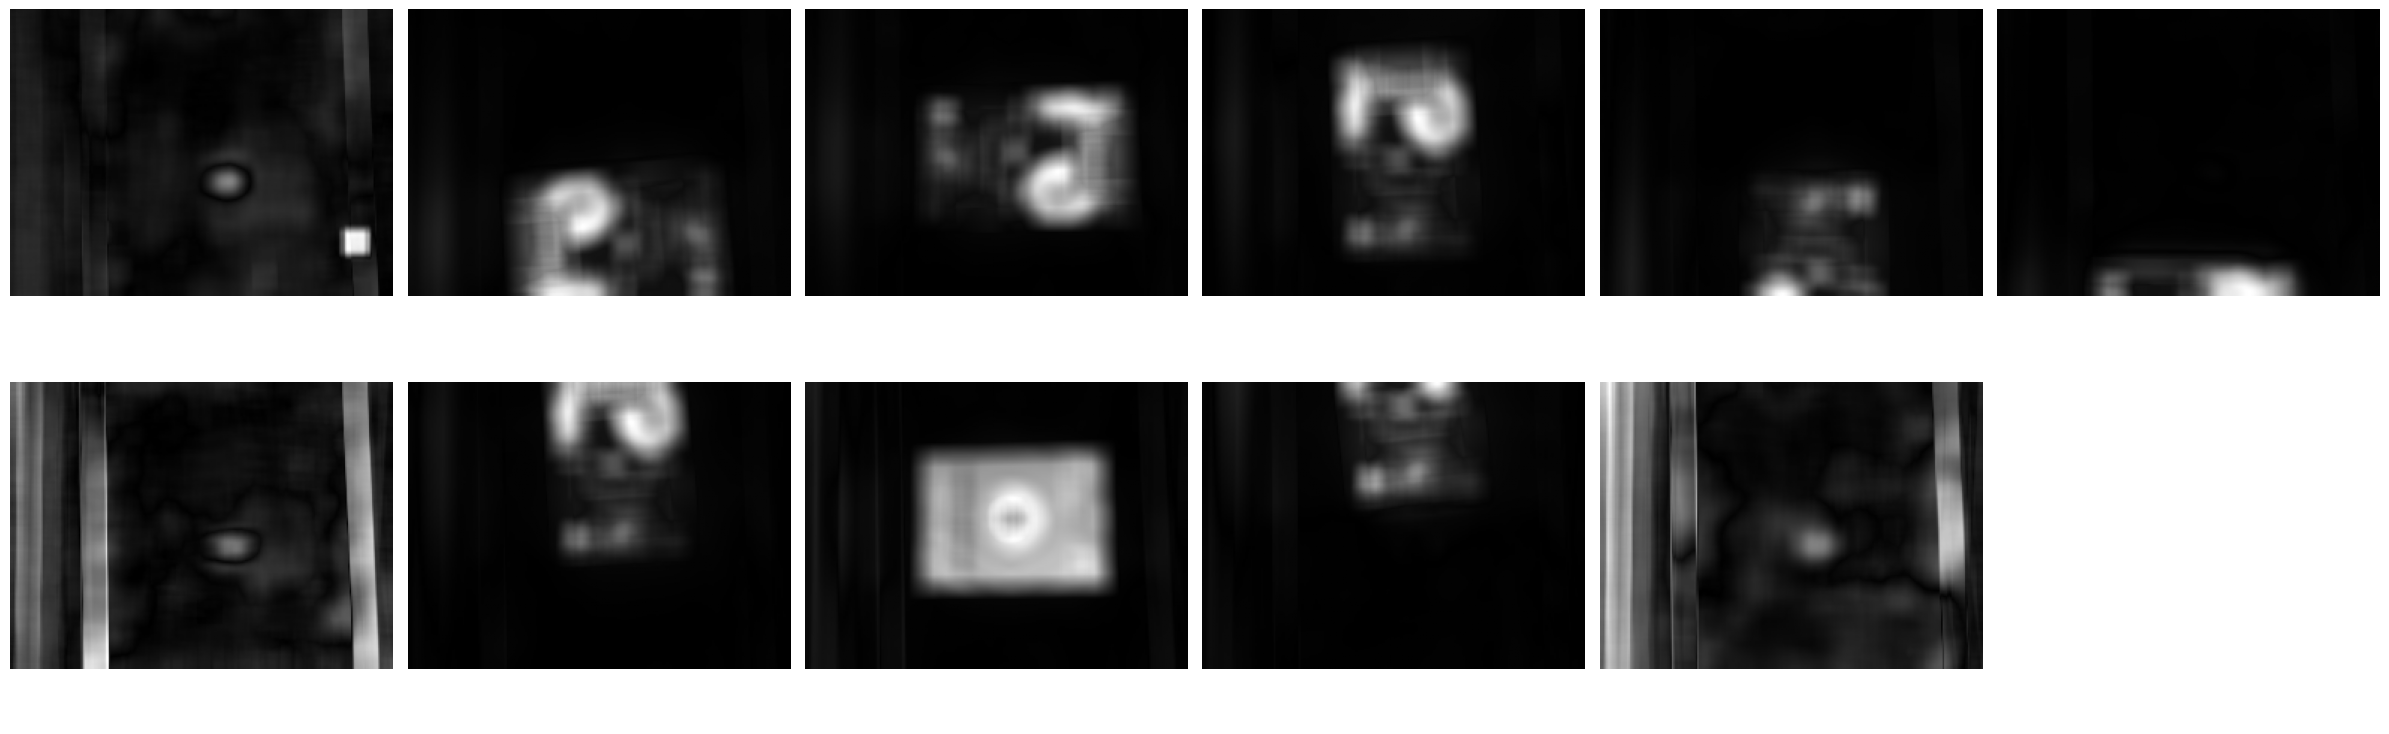

In [13]:
dilmahs_blurred_bg_subtracted_v = []
for i in range(len(dilmahs_blurred_bg_subtracted)):
    v = cv2.cvtColor(dilmahs_blurred_bg_subtracted[i], cv2.COLOR_BGR2HSV)[:,:,2]
    dilmahs_blurred_bg_subtracted_v.append(v)
dilmahs_blurred_bg_subtracted_v = np.array(dilmahs_blurred_bg_subtracted_v, dtype=np.float32)
plot_images(dilmahs_blurred_bg_subtracted_v, cols=6)

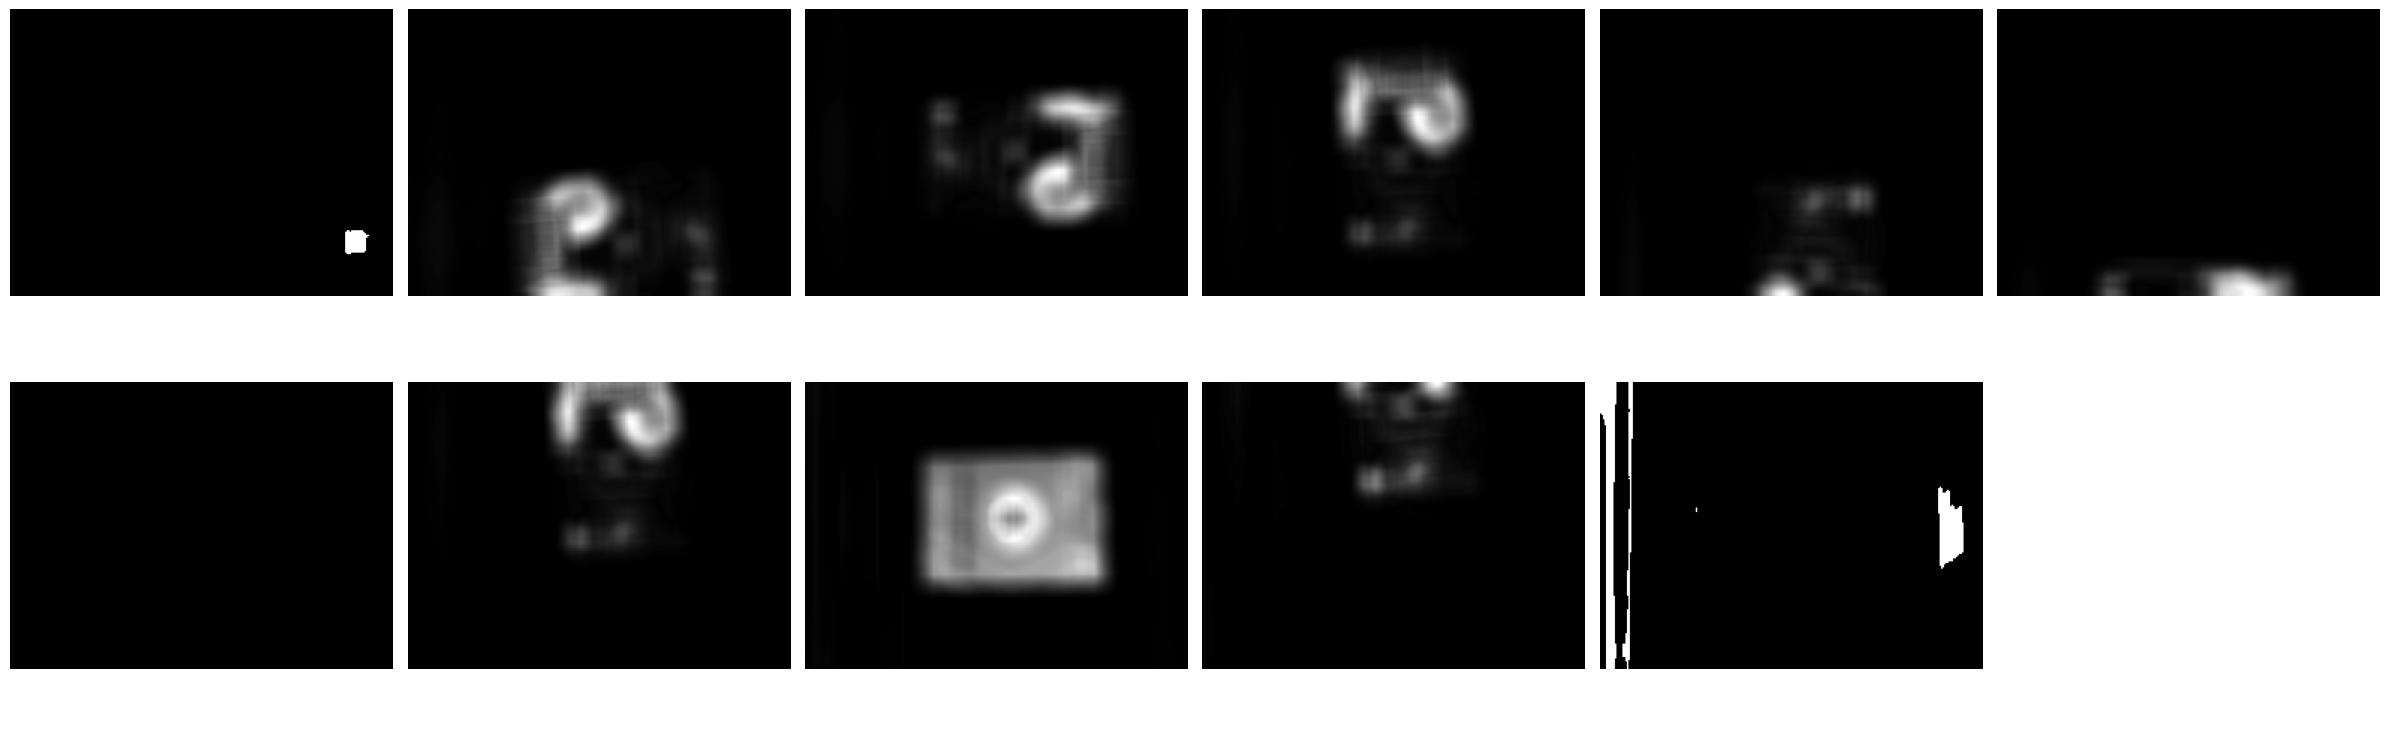

In [15]:
gamma = 1.5
table = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).astype(np.uint8)
dilmahs_blurred_bg_subtracted_v_gamma_dark_suppresion = []
for i in range(len(dilmahs_blurred_bg_subtracted_v)):
    dilmahs_blurred_bg_subtracted_v_gamma_dark_suppresion.append(cv2.LUT(dilmahs_blurred_bg_subtracted_v[i].astype(np.uint8), table))
dilmahs_blurred_bg_subtracted_v_gamma_dark_suppresion = np.array(dilmahs_blurred_bg_subtracted_v_gamma_dark_suppresion, dtype=np.float32)
plot_images(dilmahs_blurred_bg_subtracted_v_gamma_dark_suppresion.astype(np.uint8), cols=6)


### 50 thresh here is by feeling

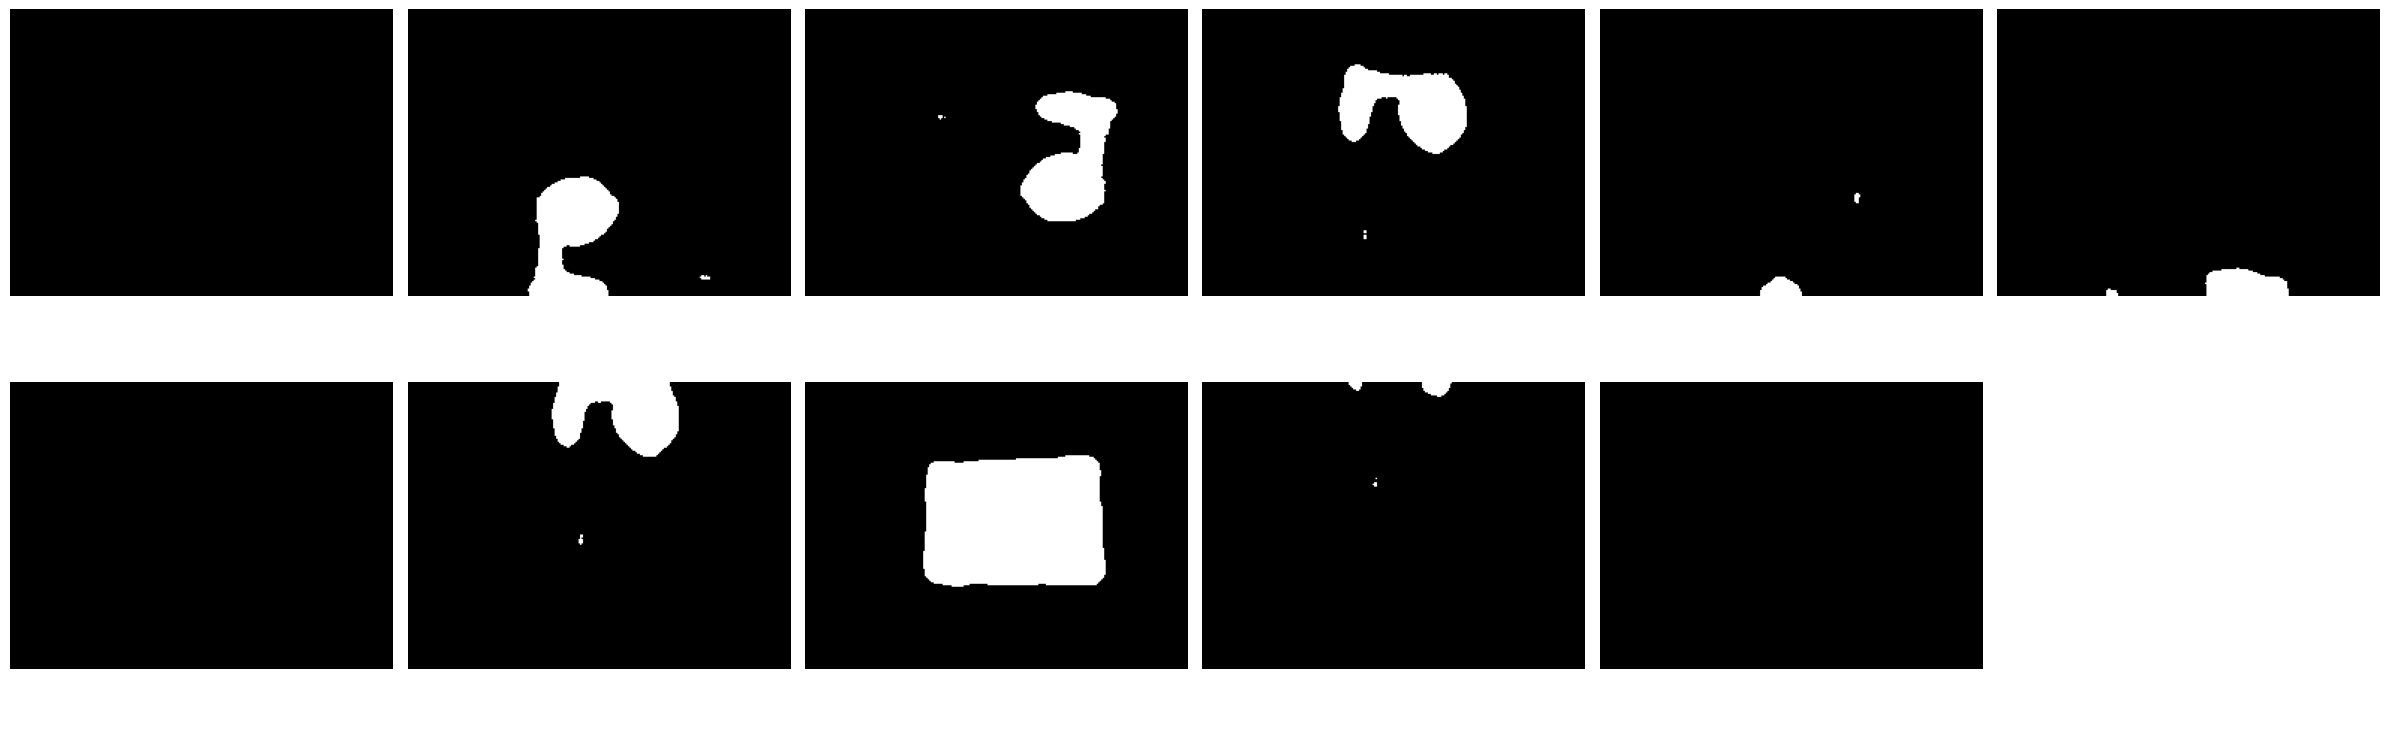

In [16]:
binaries = []
for i in range(len(dilmahs)):
    _, bin = cv2.threshold(dilmahs_blurred_bg_subtracted_v_gamma_dark_suppresion[i], 50, 255, cv2.THRESH_BINARY)
    binaries.append(bin)
binaries = np.array(binaries, dtype=np.uint8)
plot_images(binaries, cols=6)

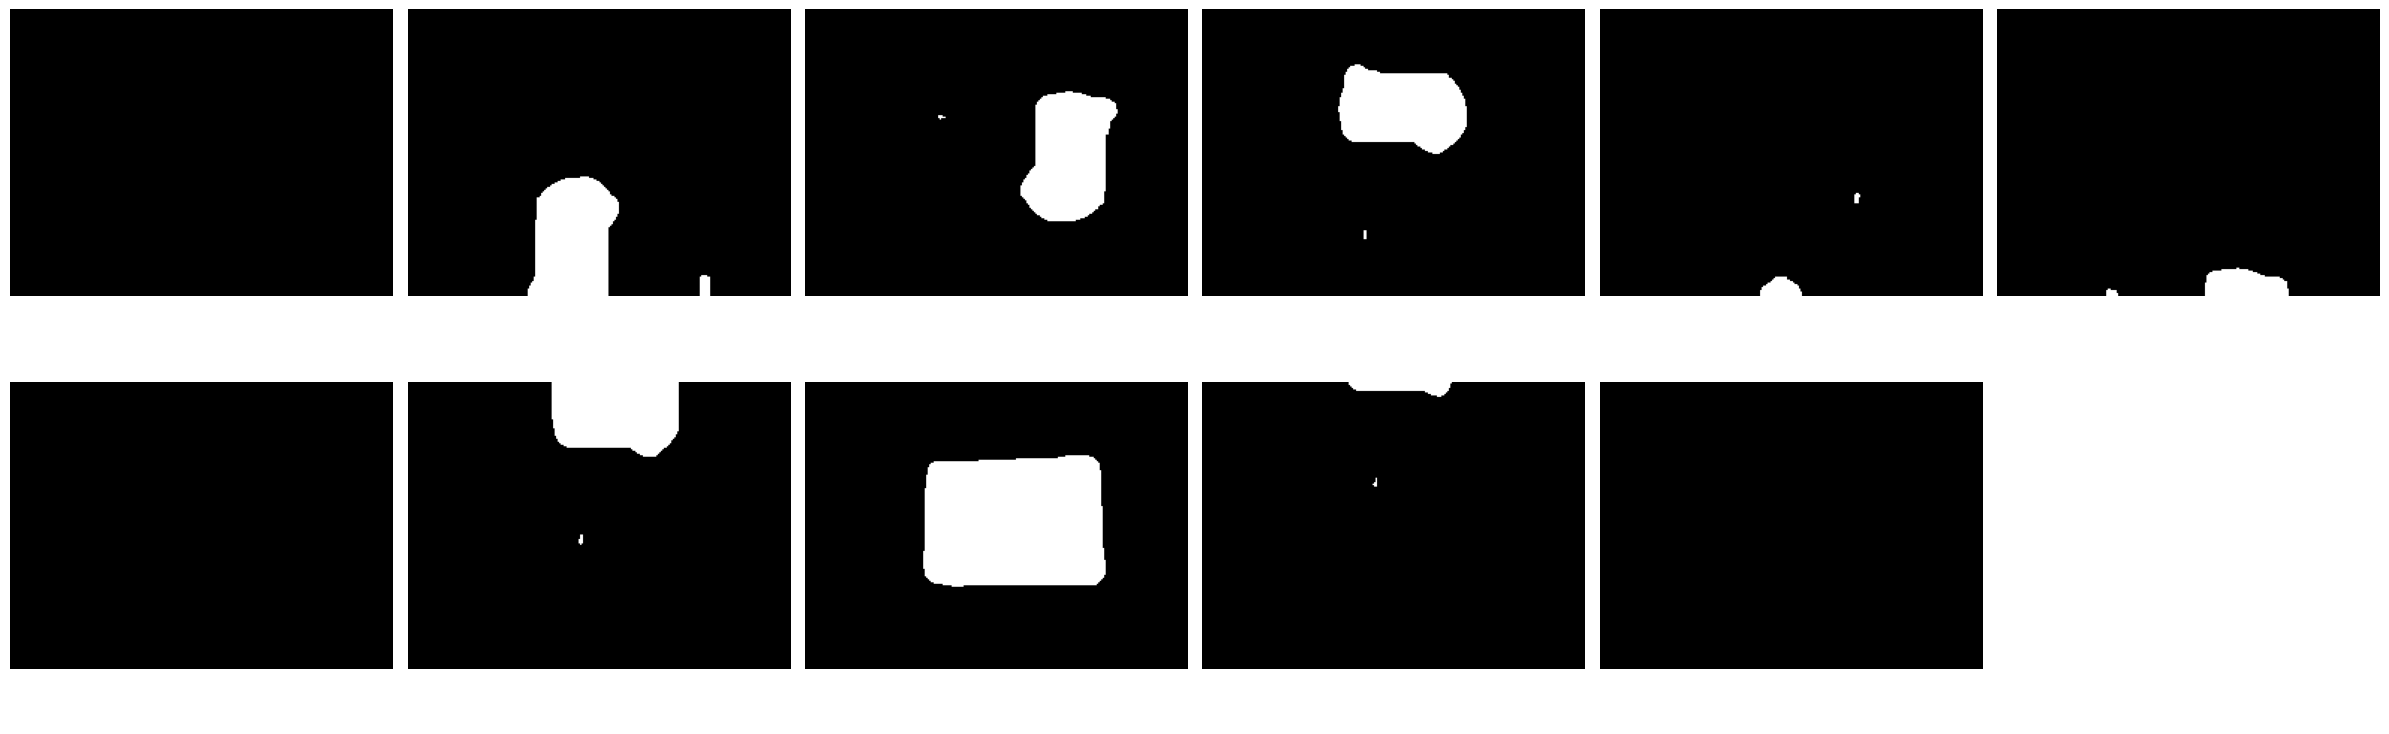

In [17]:
binaries_dilated = []
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (51,51))
for i in range(len(binaries)):
    binaries_dilated.append(cv2.morphologyEx(binaries[i], cv2.MORPH_CLOSE, kernel_close))
plot_images(binaries_dilated, cols=6)

In [18]:
final_boxes = []
for bin in binaries_dilated:
    h, w = bin.shape[:2]
    contours, _ = cv2.findContours(bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if len(contours) > 0:
        hull = cv2.convexHull(np.vstack(contours))
        x,y,bw,bh = cv2.boundingRect(hull)
    else:
        x,y,bw,bh = 0,0,w,h
    final_boxes.append((x,y,bw,bh))

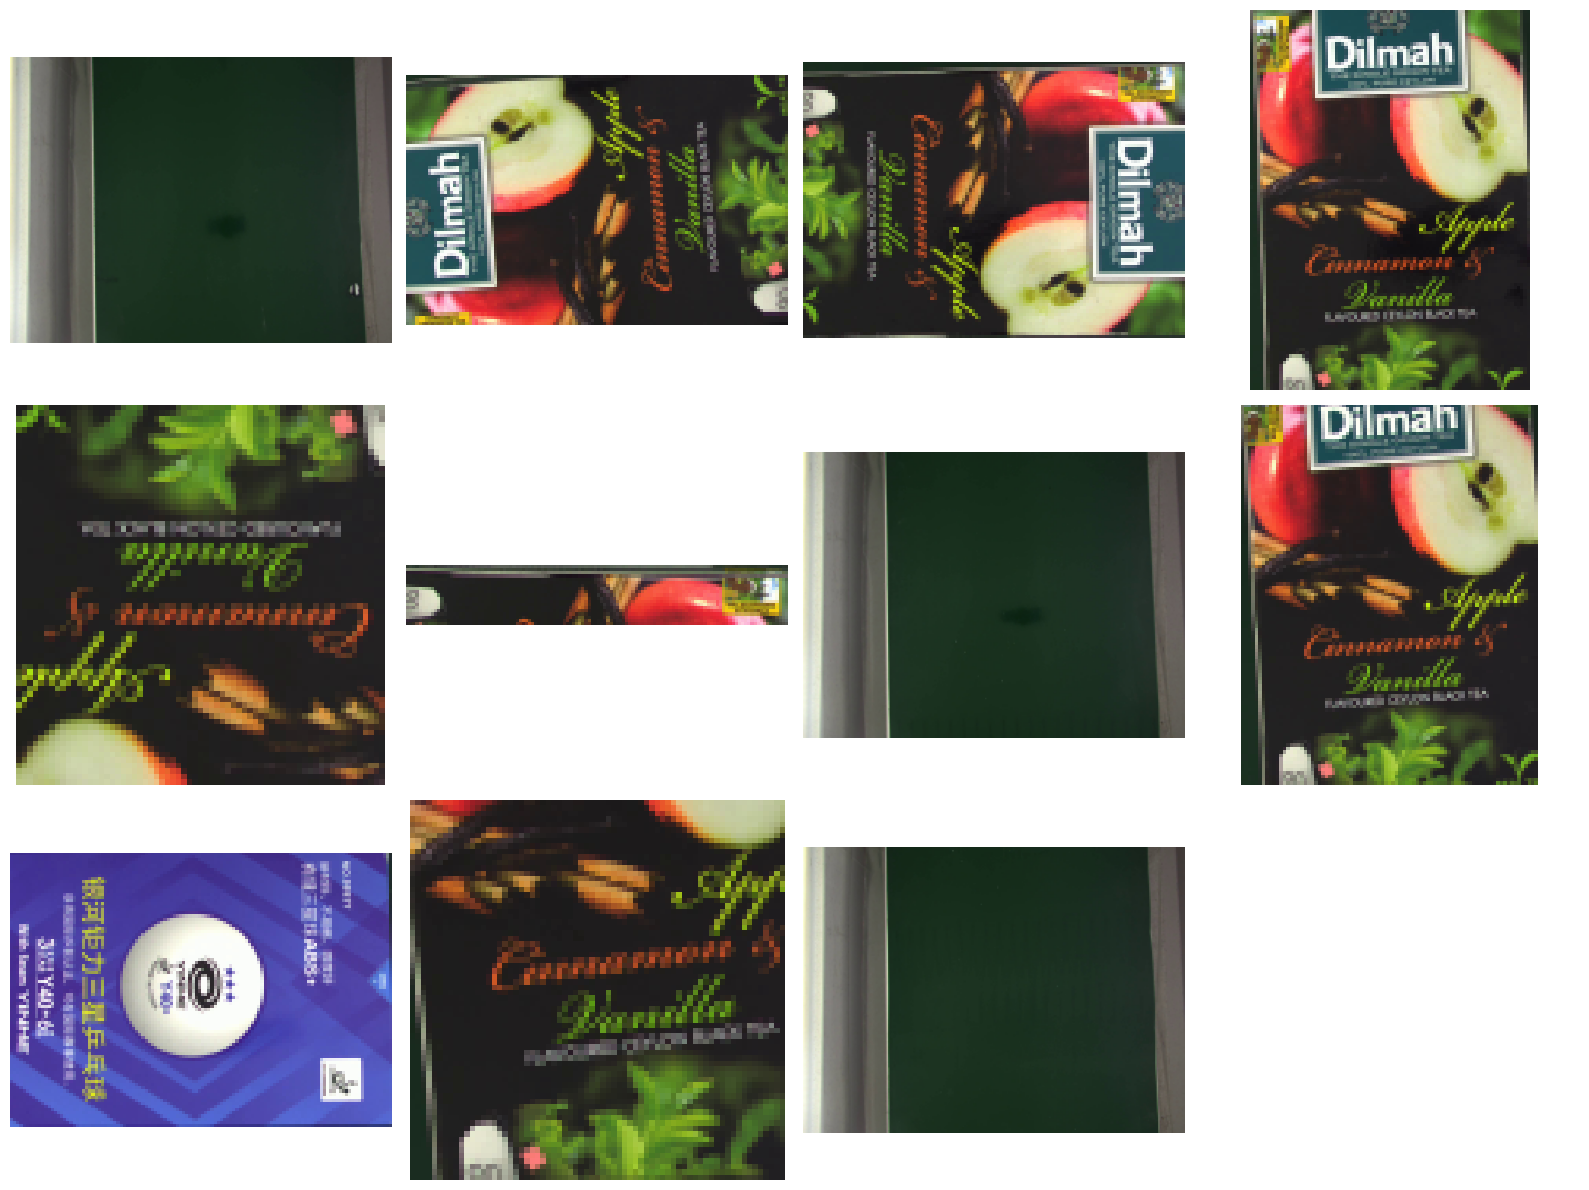

In [19]:
cropped_images = []
h,w = dilmahs[0].shape[:2]
for i in range(len(dilmahs)):
    x,y,bw,bh = final_boxes[i]
    crop = dilmahs[i][y:y+bh,x:x+bw,:]
    cropped_images.append(crop)
for i in range(len(cropped_images)):
    cropped_images[i] = cropped_images[i].astype(np.uint8)
plot_images(cropped_images, cols=4)

### reject images with bbox that y=0 or y+bw >= 1536 (view height) to avoid incomplete data

In [3]:
def create_gamma_lut(gamma: float = 2.0) -> np.ndarray:
    """Precomputed lookup table for dark suppression / gamma curve."""
    return np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).astype(np.uint8)


def resize_and_pad_to_224(crop_img: np.ndarray, target_size: int = 224) -> np.ndarray:
    """
    Resizes the larger dimension to 224.
    Forces the smaller dimension to an EVEN integer to allow symmetric integer padding,
    then pads with black borders to produce a (224, 224, 3) image.
    """
    h, w = crop_img.shape[:2]
    if h == 0 or w == 0:
        return None

    if h >= w:
        new_h = target_size
        scale = target_size / h
        new_w = int(round(w * scale))

        # Enforce even number
        if new_w % 2 != 0:
            new_w += 1 if (new_w + 1 <= target_size) else -1
        new_w = max(2, min(new_w, target_size))

        resized = cv2.resize(crop_img, (new_w, new_h), interpolation=cv2.INTER_AREA)

        pad_total = target_size - new_w
        pad_left = pad_total // 2
        pad_right = pad_total - pad_left
        padded = cv2.copyMakeBorder(
            resized, 
            top=0, bottom=0, left=pad_left, right=pad_right, 
            borderType=cv2.BORDER_CONSTANT, value=[0, 0, 0]
        )
    else:
        new_w = target_size
        scale = target_size / w
        new_h = int(round(h * scale))

        # Enforce even number
        if new_h % 2 != 0:
            new_h += 1 if (new_h + 1 <= target_size) else -1
        new_h = max(2, min(new_h, target_size))

        resized = cv2.resize(crop_img, (new_w, new_h), interpolation=cv2.INTER_AREA)

        pad_total = target_size - new_h
        pad_top = pad_total // 2
        pad_bottom = pad_total - pad_top
        padded = cv2.copyMakeBorder(
            resized, 
            top=pad_top, bottom=pad_bottom, left=0, right=0, 
            borderType=cv2.BORDER_CONSTANT, value=[0, 0, 0]
        )

    return padded


def extract_and_crop_object(
    img: np.ndarray,
    bg_blurred: np.ndarray,
    lut_table: np.ndarray = None,
    blur_ksize: tuple = (17, 17),
    thresh_val: int = 40,
    close_ksize: int = 17,
    padding_pct: float = 0.05,
    edge_margin: int = 100,
) -> np.ndarray:
    """
    Finds the object bounding box and crops it.
    
    If the bounding box touches ANY edge of the frame (top, bottom, left, right),
    it immediately skips further processing and returns None.
    """
    if lut_table is None:
        lut_table = create_gamma_lut(gamma=1.5)

    H, W = img.shape[:2]

    # 1. Blur and background subtraction
    img_blurred = cv2.blur(img, blur_ksize)
    diff = cv2.absdiff(img_blurred, bg_blurred)

    # 2. Extract V channel & apply gamma suppression
    v_channel = cv2.cvtColor(diff, cv2.COLOR_BGR2HSV)[:, :, 2]
    v_suppressed = cv2.LUT(v_channel, lut_table)

    # 3. Binary Threshold & Morphological Close
    _, binary = cv2.threshold(v_suppressed, thresh_val, 255, cv2.THRESH_BINARY)
    kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (close_ksize, close_ksize))
    mask_closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel_close)

    # 4. Find contours
    contours, _ = cv2.findContours(mask_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None

    # Convex hull of all foreground contours to get single cohesive bounding box
    all_pts = np.vstack(contours)
    hull = cv2.convexHull(all_pts)
    x, y, bw, bh = cv2.boundingRect(hull)

    # 5. STRICT EDGE CHECK: If box touches any of the 4 borders, skip!
    if (
        x <= edge_margin or 
        y <= edge_margin or 
        (x + bw) >= (W - edge_margin) or 
        (y + bh) >= (H - edge_margin)
    ):
        return None

    # 6. Apply dynamic 5% margin padding
    pad_x = int(min(x, W - (x + bw)) * padding_pct)
    pad_y = int(min(y, H - (y + bh)) * padding_pct)

    x1 = max(0, x - pad_x)
    y1 = max(0, y - pad_y)
    x2 = min(W, x + bw + pad_x)
    y2 = min(H, y + bh + pad_y)

    crop = img[y1:y2, x1:x2]

    # 7. Resize larger side to 224, enforce even smaller side, and pad to 224x224
    return resize_and_pad_to_224(crop, target_size=224)


def get_next_file_number_and_digits(
    output_dir: Path, 
    default_prefix: str = "frame_", 
    default_digits: int = 6,
    default_ext: str = ".jpg"
) -> tuple[int, int, str, str]:
    """
    Inspects existing files in `output_dir` matching patterns like `<prefix><digits>...<ext>`.
    Also correctly handles previously saved debug names like `frame001230_frame2403.jpg`.
    """
    # Group 1: prefix, Group 2: first number sequence, Group 3: optional rest/debug tag, Group 4: ext
    pattern = re.compile(r"^([a-zA-Z_\-]+?)(\d+)(_.*)?(\.[a-zA-Z0-9]+)$")
    max_idx = 0
    detected_digits = default_digits
    detected_prefix = default_prefix
    detected_ext = default_ext
    found_any = False

    if output_dir.exists():
        for f in output_dir.iterdir():
            match = pattern.match(f.name)
            if match:
                prefix, num_str, _, ext = match.groups()
                num = int(num_str)
                if num > max_idx or not found_any:
                    max_idx = max(max_idx, num)
                    detected_digits = len(num_str)
                    detected_prefix = prefix
                    detected_ext = ext
                    found_any = True

    next_idx = max_idx + 1 if found_any else 1
    return next_idx, detected_digits, detected_prefix, detected_ext


def process_conveyor_folders(
    folder_paths: list[str],
    output_dir: str,
    num_bg_frames: int = 20,
    edge_margin: int = 100,
    default_prefix: str = "frame_",
    default_digits: int = 6,
    debug: bool = False,
    image_exts: tuple = (".jpg", ".jpeg", ".png", ".bmp"),
):
    """
    Processes all images across multiple folders:
    - Automatically discovers existing numbering & digit-padding format in `output_dir`.
    - Computes mean background from first `num_bg_frames` images in each folder.
    - Crops object, skipping if the bounding box touches ANY edge.
    - Resizes larger side to 224, ensures smaller side is even, pads to 224x224.
    - Continues numbering sequentially without overwriting existing files.
    - If debug=True, appends original image name: e.g. frame001230_frame2403.jpg
    """
    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)
    lut_table = create_gamma_lut(gamma=1.5)

    # Detect current indexing, padding width, and extension dynamically
    current_index, num_digits, prefix, ext = get_next_file_number_and_digits(
        output_dir=output_path,
        default_prefix=default_prefix,
        default_digits=default_digits,
    )

    sample_name = f"{prefix}{current_index:0{num_digits}d}"
    if debug:
        sample_name += "_sourceName"
    sample_name += ext

    print(f"Detected format: prefix='{prefix}', digits={num_digits}, ext='{ext}', debug={debug}")
    print(f"Starting next save from: {sample_name}")

    total_saved = 0

    for folder_str in folder_paths:
        folder = Path(folder_str)
        if not folder.is_dir():
            print(f"Skipping invalid directory: {folder}")
            continue

        image_files = sorted([
            f for f in folder.iterdir() 
            if f.suffix.lower() in image_exts
        ])

        if len(image_files) <= num_bg_frames:
            print(f"[{folder.name}] Too few images ({len(image_files)}). Skipping.")
            continue

        print(f"[{folder.name}] Computing background from first {num_bg_frames} frames...")
        bg_frames = []
        for f in image_files[:num_bg_frames]:
            frame = cv2.imread(str(f))
            if frame is not None:
                bg_frames.append(frame)

        if not bg_frames:
            continue

        bg_mean = np.mean(bg_frames, axis=0).astype(np.uint8)
        bg_blurred = cv2.blur(bg_mean, (17, 17))

        folder_saved = 0
        for img_file in image_files[num_bg_frames:]:
            img = cv2.imread(str(img_file))
            if img is None:
                continue

            # Process & crop (returns None if touches any edge or no object)
            result = extract_and_crop_object(
                img=img,
                bg_blurred=bg_blurred,
                lut_table=lut_table,
                edge_margin=edge_margin,
            )

            if result is not None:
                base_name = f"{prefix}{current_index:0{num_digits}d}"
                if debug:
                    out_filename = f"{base_name}_{img_file.stem}{ext}"
                else:
                    out_filename = f"{base_name}{ext}"

                save_path = output_path / out_filename
                cv2.imwrite(str(save_path), result)

                current_index += 1
                folder_saved += 1
                total_saved += 1

        print(f"[{folder.name}] Saved {folder_saved} frames.")

    print(f"\nAll done! Saved {total_saved} new frames to {output_path}")


In [14]:
tocrop_folder = ['/home/filelele/personal_project/belt-conveyor-object-count/dataset/raw_frames/conveyor_video_for_train/y40.avi']
tosave_folder = '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40'
process_conveyor_folders(tocrop_folder, tosave_folder, 20, edge_margin=100)

Detected format: prefix='frame_', digits=6, ext='.jpg', debug=False
Starting next save from: frame_000989.jpg
[y40.avi] Computing background from first 20 frames...
[y40.avi] Saved 628 frames.

All done! Saved 628 new frames to /home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40
